In [23]:
library(tidyverse)
library(readxl)
library(digest)
library(repr)
library(tidymodels)
options(repr.matrix.max.rows = 6)

# DSCI 100 Group 30 Project

# Classification of User Knowledge  

## Introduction

Electrical DC machines are electro-mechanical energy conversion devices that consist of a motor that takes in electrical power through a direct electric current and converts this energy into mechanical rotational energy. Depending on the size and power of the DC motor, the mechanical energy can then be used to power everything from heavy, industrial machinery to everyday tools and appliances. The understanding and application of electrical DC machines play a crucial role in the development of many everyday objects we use.

Our group will be using the “User Knowledge Modeling Data Set” to answer the predictive question: <mark> **What is the knowledge level of a user studying Electrical DC Machines?** </mark> The dataset is from a Ph.D. thesis that looked at the development of an intuitive knowledge classifier method for modelling a set of domain-dependent data about students’ knowledge status of Electrical DC Machines. The dataset comprises six variables: 
* STG (degree of study time for goal object materials)
* SCG (degree of repetition number of user for goal object materials)
* STR (degree of study time of user for related objects with goal object)
* LPR (exam performance of user for related objects with goal object)
* PEG (exam performance of user for goal objects)
* UNS (knowledge level of user)

UNS will be the variable to predict in our model.


## Data Analysis

### Reading the file from the web

The `read_excel` function cannot directly read URL paths, so we first downloaded the file from the web then used `read_excel`.

The training and testing data in the original dataset was split between two sheets in the excel file so we loaded them in to two datasets here.

In [6]:
# Code to download file from: https://stackoverflow.com/questions/60656958/how-do-i-read-excel-file-through-url-in-r-studio-its-https
download.file("https://archive.ics.uci.edu/ml/machine-learning-databases/00257/Data_User_Modeling_Dataset_Hamdi%20Tolga%20KAHRAMAN.xls",destfile="knowledge.xls")
knowledge_raw_training <- read_excel('knowledge.xls', sheet = 2, range = "A1:F259")
knowledge_raw_testing <- read_excel('knowledge.xls', sheet = 3, range = "A1:F146")


As a precaution, we combined the training and testing datasets into 1 dataframe so we can randomly split the data into training and testing sets for our own analysis.

In [7]:
# Code to combine the dataframes from: https://www.statmethods.net/management/merging.html
knowledge_data <- rbind(knowledge_raw_training, knowledge_raw_testing)
knowledge_data

STG,SCG,STR,LPR,PEG,UNS
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
0.00,0.00,0.00,0.00,0.00,very_low
0.08,0.08,0.10,0.24,0.90,High
0.06,0.06,0.05,0.25,0.33,Low
⋮,⋮,⋮,⋮,⋮,⋮
0.56,0.60,0.77,0.13,0.32,Low
0.66,0.68,0.81,0.57,0.57,Middle
0.68,0.64,0.79,0.97,0.24,Middle


### Cleaning and wrangling the dataset

We noticed that the original dataset has two labels for the "very low" user knowledge score. These were `very_low` and `Very Low`. Here we combine these labels into one label named `Very Low`.

In [8]:
knowledge_data <- knowledge_data %>%
                    mutate(UNS = recode(UNS, very_low = 'Very Low'))

knowledge_data

STG,SCG,STR,LPR,PEG,UNS
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
0.00,0.00,0.00,0.00,0.00,Very Low
0.08,0.08,0.10,0.24,0.90,High
0.06,0.06,0.05,0.25,0.33,Low
⋮,⋮,⋮,⋮,⋮,⋮
0.56,0.60,0.77,0.13,0.32,Low
0.66,0.68,0.81,0.57,0.57,Middle
0.68,0.64,0.79,0.97,0.24,Middle


Next, we check whether our dataset has any missing values.

In [13]:
rows_missing_vals <- sum(is.na(knowledge_training))
rows_missing_vals

[1] 0

There are no missing values in our dataset.

The raw dataset seems to be clean - each column is a variable, each row is an observation and each cell is a distinct value. Since the type of the variable to predict (`UNS`, the user's knowledge level) is currently a character, we'll make it a factor with `as_factor()`.

In [9]:
# Code adapted from Chapter 6 of the course textbook
set.seed(1)
knowledge_split <- initial_split(knowledge_data, prop = 0.75, strata = UNS)
knowledge_training <- training(knowledge_split)
knowledge_testing <- testing(knowledge_split)

glimpse(knowledge_training)

Rows: 304
Columns: 6
$ STG <dbl> 0.06, 0.10, 0.09, 0.10, 0.15, 0.20, 0.00, 0.18, 0.06, 0.10, 0.10,…
$ SCG <dbl> 0.060, 0.100, 0.150, 0.100, 0.020, 0.140, 0.000, 0.180, 0.060, 0.…
$ STR <dbl> 0.05, 0.15, 0.40, 0.43, 0.34, 0.35, 0.50, 0.55, 0.51, 0.52, 0.70,…
$ LPR <dbl> 0.25, 0.65, 0.10, 0.29, 0.40, 0.72, 0.20, 0.30, 0.41, 0.78, 0.15,…
$ PEG <dbl> 0.33, 0.30, 0.66, 0.56, 0.01, 0.25, 0.85, 0.81, 0.30, 0.34, 0.90,…
$ UNS <chr> "Low", "Middle", "Middle", "Middle", "Very Low", "Low", "High", "…


## Exploratory Data Analysis

Below, we calculated the proportion of each user knowledge level label in the training dataset. There are roughly equal proportions of the `Middle` and `Low` user knowledge levels in the training dataset. About a quarter of the students had a `High` level user knowledge and 12.5% had a `Very Low` user knowledge level.

In [10]:
num_obs <- nrow(knowledge_training)

knowledge_training %>%
    group_by(UNS) %>%
    summarize(count = n(), percentage = n()/num_obs *100)

`summarise()` ungrouping output (override with `.groups` argument)



UNS,count,percentage
<chr>,<int>,<dbl>
High,77,25.32895
Low,97,31.90789
Middle,92,30.26316
Very Low,38,12.50000


<mark>placeholder to justify why we chose STG and SCG as predictors</mark>

Since we are using STG and SCG as predictors, it would be useful to find their means and standard deviations. The mean and standard deviations for our predictor variables are shown in the tables below. STG and SCG have similar means - 0.355 nd 0.351 respectively. They also have similar standard deviations of 0.214 and 0.212 respectively.

<mark>Should we talk about how the scales for both variables are similar?</mark>

In [12]:
knowledge_training_means <- knowledge_training %>% 
    select(STG, SCG) %>%
    map_df(mean) 

knowledge_training_sd <- knowledge_training %>% 
    select(STG, SCG) %>%
    map_df(sd) 

knowledge_training_means
knowledge_training_sd


STG,SCG
<dbl>,<dbl>
0.3550164,0.3509967


STG,SCG
<dbl>,<dbl>
0.2147348,0.2115421


### Visualizing the predictor variables

Below is a histogram of the distribution for the degree of study time for goal object materials(STG). The STG values are skewed right. 
<mark>Placeholder to explain any implications of skewed data</mark>

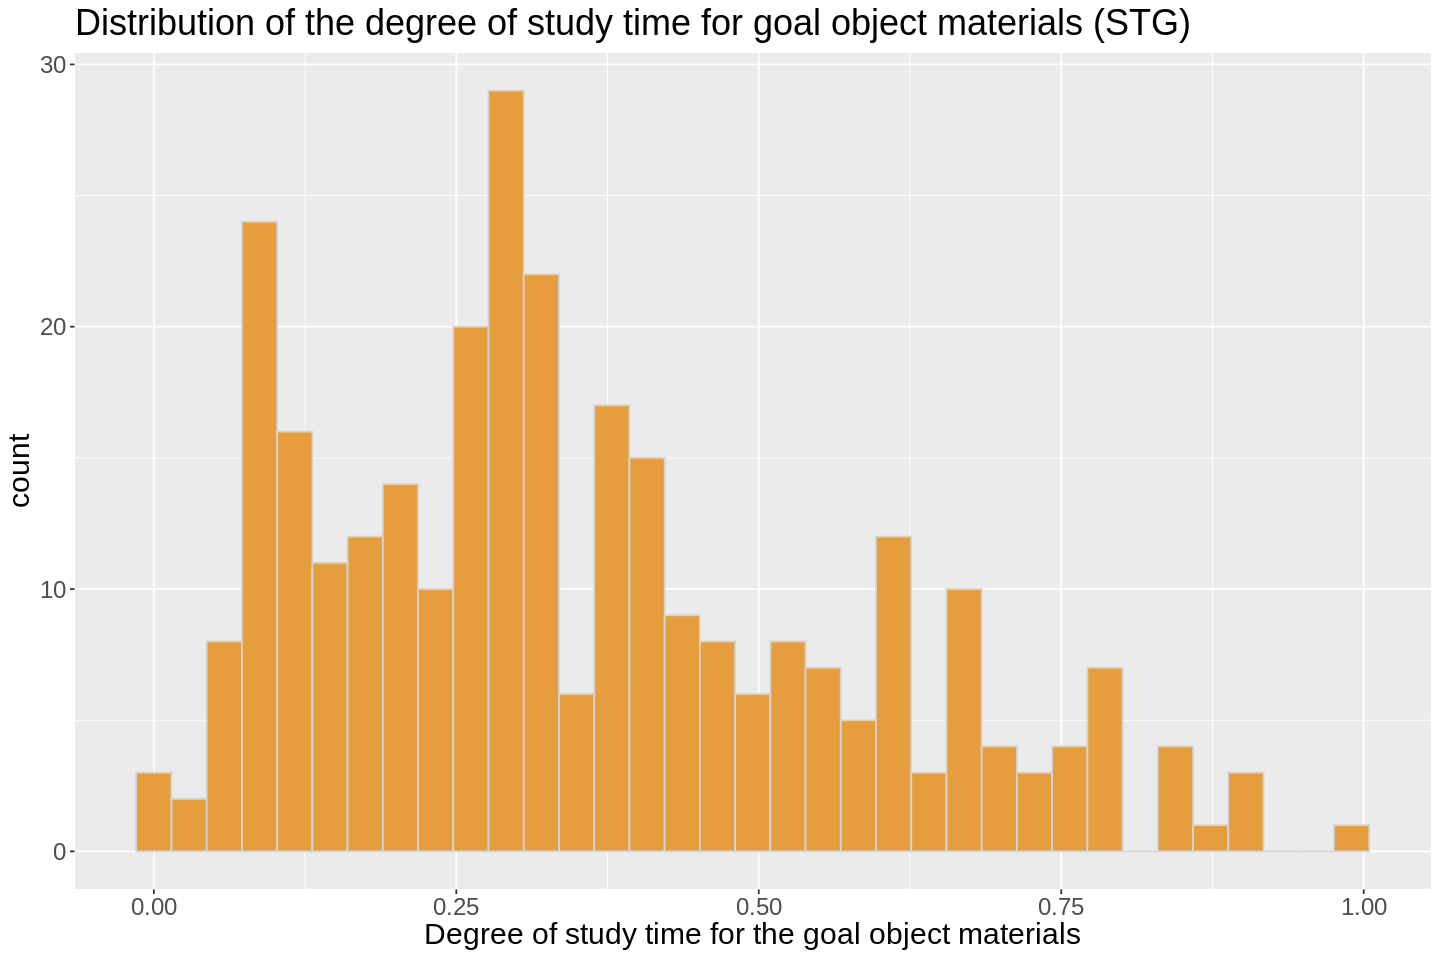

In [21]:
options(repr.plot.width = 12, repr.plot.height = 8)

stg_hist <- ggplot(knowledge_training, aes(x = STG)) +
            geom_histogram(bins = 35, color = "lightgrey", fill = "#e69d3e") + 
            ggtitle("Distribution of the degree of study time for goal object materials (STG)") + 
            xlab("Degree of study time for the goal object materials") + 
            theme(text = element_text(size = 18))  
stg_hist

<span style="color:gray">Figure 1.1 Distribution of the STG predictor variable.</span>.

Below is a histogram of the distribution of the degree of repetition for the goal object materials. The distribution has a single peak and is also right skewed.
<mark>Placeholder to explain any implications of skewed data</mark>

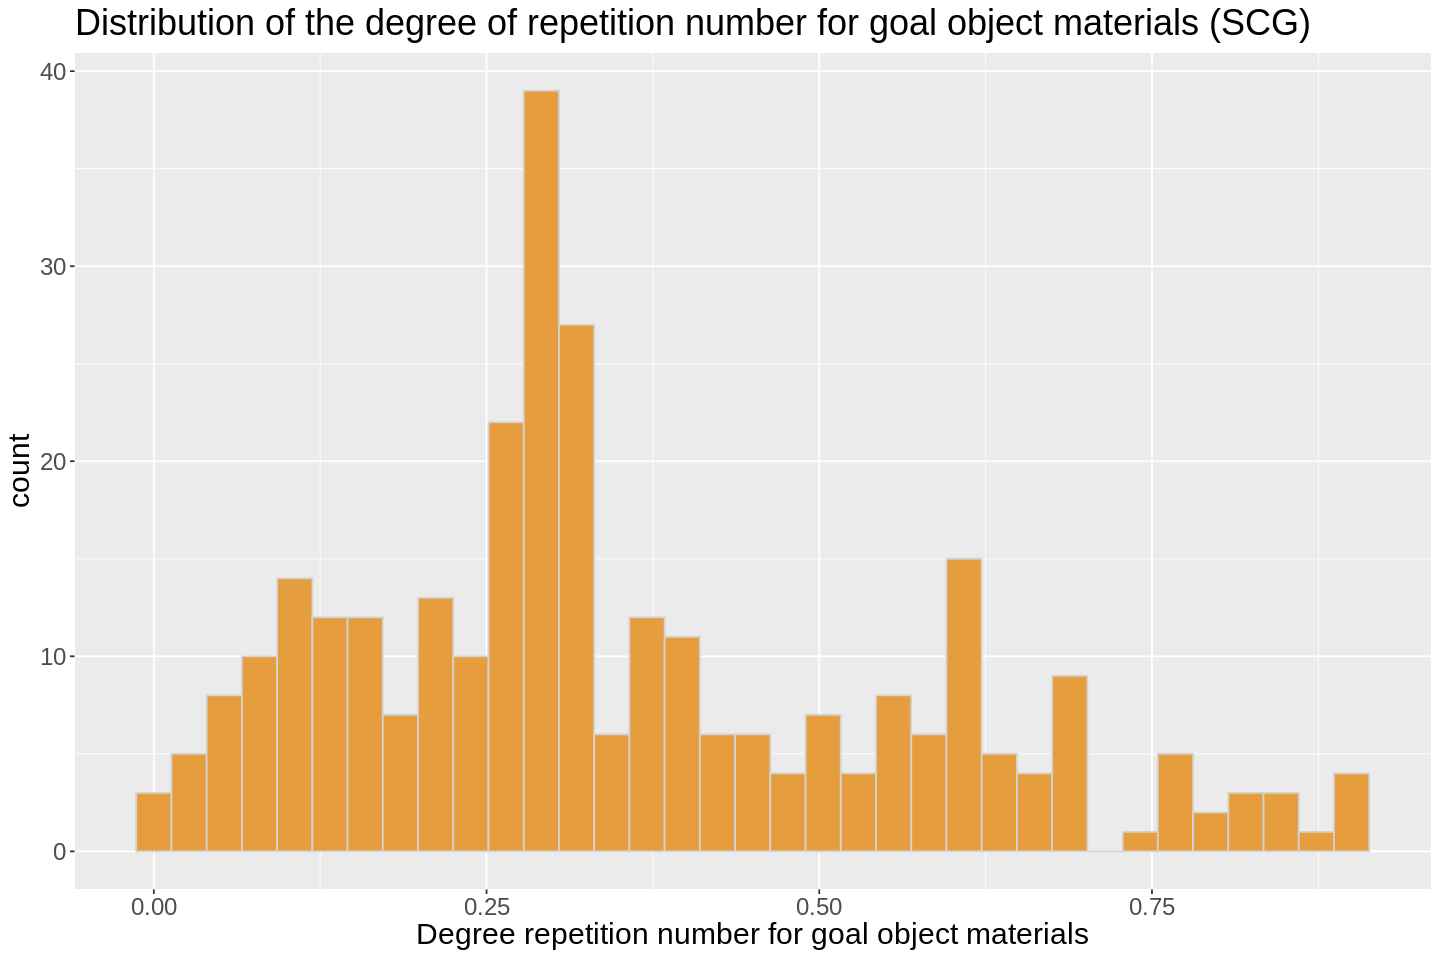

In [22]:
stg_hist <- ggplot(knowledge_training, aes(x = SCG)) +
            geom_histogram(bins = 35, color = "lightgrey", fill = "#e69d3e") + 
            ggtitle("Distribution of the degree of repetition number for goal object materials (SCG)") + 
            xlab("Degree repetition number for goal object materials") + 
            theme(text = element_text(size = 18))  
stg_hist

## Methods

We plan to use **`STG` (degree of study time for goal object materials)** and **`SCG` (degree of repetition number of user for goal object materials)** as predictor variables. We think that these will be useful for prediction because intuitively, the strength of practice (time and repetition) should have a meaningful positive relationship with a user's knowledge level.

Steps in our data analysis (K-nearest neighbors):
1. Store `STG`, `SCG` and `UNS` as a new data set. Standardize the data with `tidymodels`.
2. Use `tidymodels` to train our classifier with K = 5 initially. This involves making a model specification and using `fit` with the training set.
3. Predict the labels in the test set with our classifier.
3. Evaluate our classifier according to accuracy, the confusion matrix and the majority classifier.
4. Tune the classifier via 5-fold and 10-fold cross-validation and validation sets, using `tidymodels`'s `vfold_cv`, `fit_resamples` and `collect_metrics()`. Lastly select C = 5 or 10, whichever has a lower standard error.

Visualization of results: 
- a scatterplot of `STG` vs. `SCG` with points colored to `UNS`
- a scatterplot of accuracy vs. K to decide which K is best

## Expected outcomes and significance

From the question proposed and the brief exploratory data analysis conducted, we expect to find that people who spend more time in school have a higher knowledge level and have higher scores for their exam performance. The impact of these findings could show the necessity of schooling in the field. The outcomes of this project could lead to future questions about the relation between knowledge and the specific program or school that each of the participants is a part of. This could be used to improve the quality of schooling although it would consist of collecting a new set of data since the current data set does not contain this information. 